# T-RAG · Notebook 2 — Sentiment, timelines, embeddings and the sentiment–price tests (GPU)

## About this notebook

**What it does :** This notebook turns the news articles from Notebook 1 into numbers the system can search and reason with. First, **FinBERT**, a model trained on financial text, labels every article positive, negative or neutral. The main score uses only the sentences that mention the article's own company. So a headline like "Intel slumps after AMD unveils faster chips" counts as bad news for Intel and good news for AMD. A simple finance word-list method (Loughran–McDonald) is also scored, as a baseline.

From these labels it builds daily, weekly and monthly **sentiment timelines** for each company, using net tone = (positive − negative) / (positive + negative + 1). The FNSPID news has no 2021–2023 articles for Meta and Netflix, so news covers eight companies. The notebook records each company's coverage period.

Second, it creates **bge-base embeddings** (vectors) of every article for search, and runs the **time-blindness test**. Asked "What happened to Tesla in 2022?" with no date filter, plain semantic search returns only 68% of its top 20 results from the year asked.

Third, it tests whether news mood is linked to stock moves. The link is clear on the same day (correlation 0.21), but mood does not reliably predict the next days' returns. No Granger test stays significant after correcting for running 48 tests.

**Needs :** Notebook 1's output. GPU T4, with about 10–20 minutes of GPU time. Internet on.

**Produces :** `trag_index/` with the scored articles (`chunks.parquet`), the embeddings, the sentiment timelines, and the analysis tables and figures.

In [1]:
# ============================ CONFIG ============================
from pathlib import Path

FINBERT_MODEL = "ProsusAI/finbert"
EMBED_MODEL = "BAAI/bge-base-en-v1.5"
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "   # bge's recommended query prefix

END = "2023-12-31"
MIN_DOCS_TICKER = 1000      # tickers with fewer news documents are dropped (META and NFLX have none)
MIN_MONTH_DOCS = 40         # a ticker's coverage starts at the first month with at least this many documents
MIN_WEEK_DOCS = 5           # weeks with fewer documents are marked "insufficient data"
FINBERT_BATCH, FINBERT_MAXLEN = 128, 256
EMB_BATCH = 256
MAX_LAG = 3                 # lags (trading days) for lead-lag and Granger tests

ON_KAGGLE = Path("/kaggle/working").exists()
OUT = Path("/kaggle/working/trag_index") if ON_KAGGLE else Path("trag_index")
(OUT / "analysis").mkdir(parents=True, exist_ok=True)
(OUT / "figures").mkdir(parents=True, exist_ok=True)
print("Output folder:", OUT.resolve())

Output folder: /kaggle/working/trag_index


In [2]:
!pip install -q sentence-transformers pysentiment2

In [3]:
import re, io, json, time, glob, shutil, warnings, contextlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=SyntaxWarning)
pd.set_option("display.width", 170, "display.max_columns", 30)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "⚠️ no GPU — this will be slow")
SUMMARY = {}       # key numbers printed at the end
T0 = time.time()

torch 2.11.0+cu130 | device: cuda | Tesla T4


## Step 1 — Load Notebook 1's tables and measure coverage

The FNSPID news has **no articles for META or NFLX** in 2021–2023, so they are dropped. Coverage also starts at different times (for example, TSLA from about April 2022, AMZN only in 2023). Each ticker's **coverage period** starts at the first month with at least 40 articles. Notebook 3 uses it to add honest coverage notes ("news coverage for AMZN starts in January 2023") and to create unanswerable test questions.

**Timestamps:** almost all FNSPID articles carry a date only (`00:00:00`), with no time of day. So:
* `day0`: the article's own date (the same-day mapping);
* `day0_safe`: the **next** trading day after that date, the first day the market *certainly* had the article. It's used wherever look-ahead matters.

In [4]:
def find_input(name):
    hits = sorted(glob.glob(f"/kaggle/input/**/trag_data/{name}", recursive=True)) + \
           sorted(glob.glob(f"trag_data/{name}"))
    if not hits:
        raise FileNotFoundError(f"{name} not found. Attach Notebook 1's output (Add Data → Notebook Output Files).")
    return hits[0]

docs = pd.read_parquet(find_input("documents.parquet"))
prices = pd.read_parquet(find_input("prices.parquet"))
events = pd.read_parquet(find_input("events.parquet"))
trading_days = pd.read_parquet(find_input("trading_days.parquet"))
TRADING_DAYS = pd.DatetimeIndex(trading_days["date"])
TD = TRADING_DAYS.values.astype("datetime64[ns]")
print("Loaded from", Path(find_input("documents.parquet")).parent)
print(f"documents {len(docs):,} | prices {len(prices):,} | events {len(events):,}")

def next_trading_day(dates, same_day_ok=True):
    d = pd.to_datetime(pd.Series(dates)).dt.normalize().values.astype("datetime64[ns]")
    idx = np.searchsorted(TD, d, side="left" if same_day_ok else "right")
    out = np.full(len(d), np.datetime64("NaT", "ns"), dtype="datetime64[ns]")
    ok = idx < len(TD)
    out[ok] = TD[idx[ok]]
    return pd.DatetimeIndex(out)

# --- keep tickers that have news
counts = docs.ticker.value_counts()
NEWS_TICKERS = sorted(counts[counts >= MIN_DOCS_TICKER].index.tolist())
dropped = sorted(set(prices.ticker.unique()) - set(NEWS_TICKERS) - {"QQQ"})
print("Tickers with news:", NEWS_TICKERS, "| dropped (no/thin news):", dropped)
docs = docs[docs.ticker.isin(NEWS_TICKERS)].reset_index(drop=True)
docs["day0"] = pd.to_datetime(docs["day0"])

# --- conservative trading-day mapping for date-only timestamps
cal_date = docs.published_at.dt.tz_convert("UTC").dt.tz_localize(None).dt.normalize()
safe = next_trading_day(cal_date.values, same_day_ok=False)
docs["day0_safe"] = np.where(docs.time_missing, safe, docs.day0.values)
docs["day0_safe"] = pd.to_datetime(docs["day0_safe"])
print("Share of documents with date-only timestamps:", round(docs.time_missing.mean(), 3))

# --- coverage period per ticker
month = docs.day0.dt.to_period("M")
mcount = docs.groupby([docs.ticker, month]).size().rename("n").reset_index()
rows = []
for t in NEWS_TICKERS:
    m = mcount[(mcount.ticker == t) & (mcount.n >= MIN_MONTH_DOCS)]
    start = m.day0.min().to_timestamp() if len(m) else docs.loc[docs.ticker == t, "day0"].min()
    d_t = docs[docs.ticker == t]
    rows.append({"ticker": t, "coverage_start": start, "coverage_end": d_t.day0.max(),
                 "n_docs": len(d_t), "docs_per_week": round(len(d_t[d_t.day0 >= start]) /
                 max(1, (d_t.day0.max() - start).days / 7), 1)})
coverage_span = pd.DataFrame(rows)
COV_START = dict(zip(coverage_span.ticker, coverage_span.coverage_start))
print(coverage_span.to_string(index=False))
SUMMARY["coverage"] = {r.ticker: f"{r.coverage_start:%Y-%m}→{r.coverage_end:%Y-%m} ({r.n_docs} docs)"
                       for r in coverage_span.itertuples()}

Loaded from /kaggle/input/notebooks/sriharshakontham/trag-01-data-events/trag_data
documents 49,993 | prices 10,967 | events 718
Tickers with news: ['AAPL', 'AMD', 'AMZN', 'GOOGL', 'INTC', 'MSFT', 'NVDA', 'TSLA'] | dropped (no/thin news): ['META', 'NFLX']
Share of documents with date-only timestamps: 0.997
ticker coverage_start coverage_end  n_docs  docs_per_week
  AAPL     2022-06-01   2023-12-18    8002           99.1
   AMD     2021-01-01   2024-01-02    4465           28.5
  AMZN     2023-03-01   2023-12-18    4293          102.9
 GOOGL     2021-01-01   2023-12-18    5077           32.9
  INTC     2021-01-01   2023-12-18    4411           28.6
  MSFT     2022-04-01   2023-12-18    7926           88.6
  NVDA     2021-08-01   2023-12-18    7879           63.5
  TSLA     2022-05-01   2023-12-18    7940           93.3


In [5]:
# --- readable event labels (used by Notebook 3)
def event_label(row):
    et = row.event_types
    if "earnings" in et:
        # Tesla also files its quarterly *delivery* reports under 8-K item 2.02, in the first days of a quarter
        if row.ticker == "TSLA" and pd.Timestamp(row.event_date).day <= 5:
            return "deliveries report"
        return "earnings"
    if "leadership" in et: return "leadership change"
    if "fomc" in et:       return "FOMC decision"
    return "price shock"
events["day0"] = pd.to_datetime(events.day0)
events["label"] = events.apply(event_label, axis=1)
print(events[events.ticker_scope != "ALL"].label.value_counts().to_string())

label
price shock          269
earnings             124
leadership change     73
deliveries report     12


## Step 2 — FinBERT sentiment (GPU)

Every document gets three FinBERT scores, each `p(positive) − p(negative)` between −1 and +1:
* `s_title`: the headline alone;
* `s_full`: headline + summary (the `text_for_scoring` from Notebook 1);
* `s_target`: only the **sentences that mention the document's own company**, averaged. This handles headlines like *"Intel slumps after AMD unveils faster chips"*, which mean different things for INTC and AMD.

**`s_target` is the main score.** Identical texts are scored once, and texts are sorted by length to avoid padding waste.

In [6]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

ALIASES = {
    "TSLA": ["tesla", "tsla"], "AAPL": ["apple", "aapl", "iphone"], "MSFT": ["microsoft", "msft"],
    "NVDA": ["nvidia", "nvda"], "AMZN": ["amazon", "amzn", "aws"],
    "META": ["meta platforms", "meta", "facebook", "fb", "instagram", "whatsapp"],
    "GOOGL": ["alphabet", "google", "googl", "goog", "youtube"], "NFLX": ["netflix", "nflx"],
    "AMD": ["amd", "advanced micro devices"], "INTC": ["intel", "intc"]}
ALIAS_RE = {t: re.compile(r"\b(?:" + "|".join(map(re.escape, a)) + r")\b", re.I) for t, a in ALIASES.items()}

tok = AutoTokenizer.from_pretrained(FINBERT_MODEL)
fb = AutoModelForSequenceClassification.from_pretrained(FINBERT_MODEL).to(DEVICE).eval()
if DEVICE == "cuda":
    fb = fb.half()
id2label = {int(k): v.lower() for k, v in fb.config.id2label.items()}
COLS = [next(i for i, v in id2label.items() if v.startswith(p)) for p in ("pos", "neg", "neu")]
print("FinBERT labels:", id2label, "→ column order [pos, neg, neu] =", COLS)

def finbert_probs(texts, name=""):
    texts = pd.Series(list(texts), dtype="object").fillna("").astype(str)
    uniq, inv = np.unique(texts.values, return_inverse=True)
    order = np.argsort([len(u) for u in uniq])
    probs = np.zeros((len(uniq), 3), dtype=np.float32)
    t0, nb = time.time(), int(np.ceil(len(uniq) / FINBERT_BATCH))
    with torch.inference_mode():
        for b in range(nb):
            idx = order[b * FINBERT_BATCH:(b + 1) * FINBERT_BATCH]
            enc = tok([uniq[i] for i in idx], padding=True, truncation=True,
                      max_length=FINBERT_MAXLEN, return_tensors="pt").to(DEVICE)
            p = fb(**enc).logits.float().softmax(-1).cpu().numpy()
            probs[idx] = p[:, COLS]
            if b % 100 == 0 or b == nb - 1:
                print(f"  {name}: batch {b+1}/{nb} | {time.time()-t0:5.0f}s")
    return probs[inv]

def to_label(p):
    return np.array(["positive", "negative", "neutral"])[p.argmax(1)]

t_fb = time.time()
P_title = finbert_probs(docs.title, "headlines")
P_full = finbert_probs(docs.text_for_scoring, "headline+summary")

# company-specific sentences
SPLIT = re.compile(r"(?<=[.!?])\s+")
pairs = []
for i, (t, txt, title) in enumerate(zip(docs.ticker, docs.text_for_scoring, docs.title)):
    sents = [s for s in SPLIT.split(str(txt)) if len(s) >= 20 and ALIAS_RE[t].search(s)]
    for s in (sents or [title]):
        pairs.append((i, s))
pair_doc = np.array([p[0] for p in pairs])
P_sent = finbert_probs([p[1] for p in pairs], "target sentences")
P_target = np.zeros((len(docs), 3), dtype=np.float32)
np.add.at(P_target, pair_doc, P_sent)
P_target /= np.bincount(pair_doc, minlength=len(docs))[:, None]
SUMMARY["finbert_seconds"] = round(time.time() - t_fb)

for name, P in [("title", P_title), ("full", P_full), ("target", P_target)]:
    docs[f"s_{name}"] = P[:, 0] - P[:, 1]
    docs[f"label_{name}"] = to_label(P)
docs[["p_pos", "p_neg", "p_neu"]] = P_target
docs["score"], docs["label"] = docs.s_target, docs.label_target
print(f"\nFinBERT done in {time.time()-t_fb:.0f}s for {len(docs):,} docs + {len(pairs):,} sentences")
print("Main label distribution:", docs.label.value_counts(normalize=True).round(3).to_dict())
SUMMARY["label_share"] = docs.label.value_counts(normalize=True).round(3).to_dict()
del fb; torch.cuda.empty_cache() if DEVICE == "cuda" else None

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

FinBERT labels: {0: 'positive', 1: 'negative', 2: 'neutral'} → column order [pos, neg, neu] = [0, 1, 2]
  headlines: batch 1/266 |     2s
  headlines: batch 101/266 |     5s
  headlines: batch 201/266 |     9s
  headlines: batch 266/266 |    12s
  headline+summary: batch 1/344 |     0s
  headline+summary: batch 101/344 |    24s
  headline+summary: batch 201/344 |    54s
  headline+summary: batch 301/344 |    94s
  headline+summary: batch 344/344 |   111s
  target sentences: batch 1/653 |     0s
  target sentences: batch 101/653 |     4s
  target sentences: batch 201/653 |     9s
  target sentences: batch 301/653 |    17s
  target sentences: batch 401/653 |    26s
  target sentences: batch 501/653 |    37s
  target sentences: batch 601/653 |    52s
  target sentences: batch 653/653 |    63s

FinBERT done in 187s for 49,993 docs + 108,511 sentences
Main label distribution: {'neutral': 0.546, 'positive': 0.255, 'negative': 0.198}


## Step 3 — Word-list baseline (Loughran–McDonald)

This counts finance-specific positive and negative words. It's a simple, interpretable baseline that FinBERT should beat.

In [7]:
try:
    import pysentiment2 as ps
    lm = ps.LM()
    t_lm = time.time()
    lm_scores = [lm.get_score(lm.tokenize(str(x))) for x in docs.text_for_scoring]
    pos = np.array([s["Positive"] for s in lm_scores], dtype=float)
    neg = np.array([s["Negative"] for s in lm_scores], dtype=float)
    docs["s_lexicon"] = (pos - neg) / (pos + neg + 1e-6)
    docs["label_lexicon"] = np.where(pos > neg, "positive", np.where(neg > pos, "negative", "neutral"))
    print(f"Lexicon scored in {time.time()-t_lm:.0f}s:", docs.label_lexicon.value_counts(normalize=True).round(3).to_dict())
except Exception as e:
    print("⚠️ Lexicon baseline skipped:", e)
    docs["s_lexicon"], docs["label_lexicon"] = np.nan, None

docs.to_parquet(OUT / "documents_scored.parquet", index=False)      # checkpoint
print("Saved documents_scored.parquet")

Lexicon scored in 46s: {'negative': 0.372, 'positive': 0.365, 'neutral': 0.263}
Saved documents_scored.parquet


## Step 5 — Sentiment timelines

For each ticker and each day, week (ending Friday) and month:
* `n_docs`, `n_pos`, `n_neg`, `n_neu`;
* `mean_score` (average of the main score) and its `std_err`;
* **`net_tone` = (n_pos − n_neg) / (n_pos + n_neg + 1)**;
* `relative_tone`: the ticker's net tone minus the average over all tickers that period (removes the market-wide mood);
* `insufficient`: True if fewer than 5 documents (weekly) or 20 (monthly).

Notebook 3's timeline tool reads these tables.

In [ ]:
LABELS = ["positive", "negative", "neutral"]

def aggregate(df, key, freq=None, min_docs=1):
    g = df.copy()
    for l in LABELS:
        g[f"n_{l[:3]}"] = (g.label == l).astype(int)
    grouper = [g.ticker, pd.Grouper(key=key, freq=freq)] if freq else [g.ticker, g[key]]
    a = g.groupby(grouper).agg(n_docs=("doc_id", "size"), n_pos=("n_pos", "sum"), n_neg=("n_neg", "sum"),
                               n_neu=("n_neu", "sum"), mean_score=("score", "mean"), std_score=("score", "std"))
    a = a[a.n_docs > 0].reset_index().rename(columns={key: "period"})
    a["net_tone"] = (a.n_pos - a.n_neg) / (a.n_pos + a.n_neg + 1)
    a["std_err"] = a.std_score / np.sqrt(a.n_docs)
    a["insufficient"] = a.n_docs < min_docs
    ok = a[~a.insufficient]
    mkt = ok.groupby("period").net_tone.mean().rename("market_tone")
    a = a.merge(mkt, on="period", how="left")
    a["relative_tone"] = a.net_tone - a.market_tone
    return a.drop(columns=["std_score"])

sent_daily = aggregate(docs, "day0")
sent_weekly = aggregate(docs, "day0", "W-FRI", MIN_WEEK_DOCS)
sent_monthly = aggregate(docs, "day0", "MS", 20)
for name, tab in [("daily", sent_daily), ("weekly", sent_weekly), ("monthly", sent_monthly)]:
    tab.to_parquet(OUT / f"sentiment_{name}.parquet", index=False)
print(f"daily {len(sent_daily):,} rows | weekly {len(sent_weekly):,} | monthly {len(sent_monthly):,}")
print("\nMonthly net tone (sufficient months only):")
piv = sent_monthly[~sent_monthly.insufficient].pivot(index="period", columns="ticker", values="net_tone")
print(piv.round(2).tail(24).to_string())

daily 4,189 rows | weekly 887 | monthly 208

Monthly net tone (sufficient months only):
ticker      AAPL   AMD  AMZN  GOOGL  INTC  MSFT  NVDA  TSLA
period                                                     
2022-01-01   NaN  0.49   NaN   0.21  0.31   NaN  0.19   NaN
2022-02-01   NaN  0.64   NaN   0.46  0.32   NaN  0.15   NaN
2022-03-01   NaN  0.57   NaN   0.15  0.29   NaN  0.27   NaN
2022-04-01   NaN  0.02   NaN   0.30 -0.10  0.30 -0.15   NaN
2022-05-01   NaN  0.43   NaN  -0.02 -0.14  0.11  0.08 -0.17
2022-06-01 -0.05  0.02   NaN   0.11 -0.49 -0.14  0.01 -0.25
2022-07-01 -0.01  0.04   NaN  -0.21 -0.15  0.10 -0.03  0.02
2022-08-01  0.10 -0.01   NaN   0.18 -0.23 -0.09 -0.42 -0.03
2022-09-01 -0.18 -0.19   NaN   0.03 -0.05 -0.08 -0.41 -0.07
2022-10-01 -0.04 -0.35   NaN  -0.43 -0.12 -0.19 -0.16 -0.22
2022-11-01 -0.31  0.14   NaN   0.08 -0.24 -0.15 -0.10 -0.12
2022-12-01 -0.40  0.08   NaN  -0.05 -0.30 -0.05 -0.17 -0.46
2023-01-01 -0.12 -0.04   NaN  -0.36 -0.38 -0.33  0.10 -0.12
2023-02-01 -

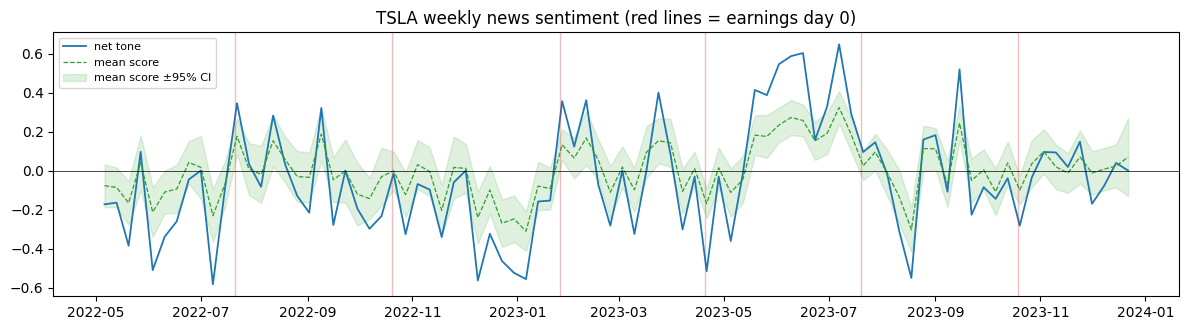

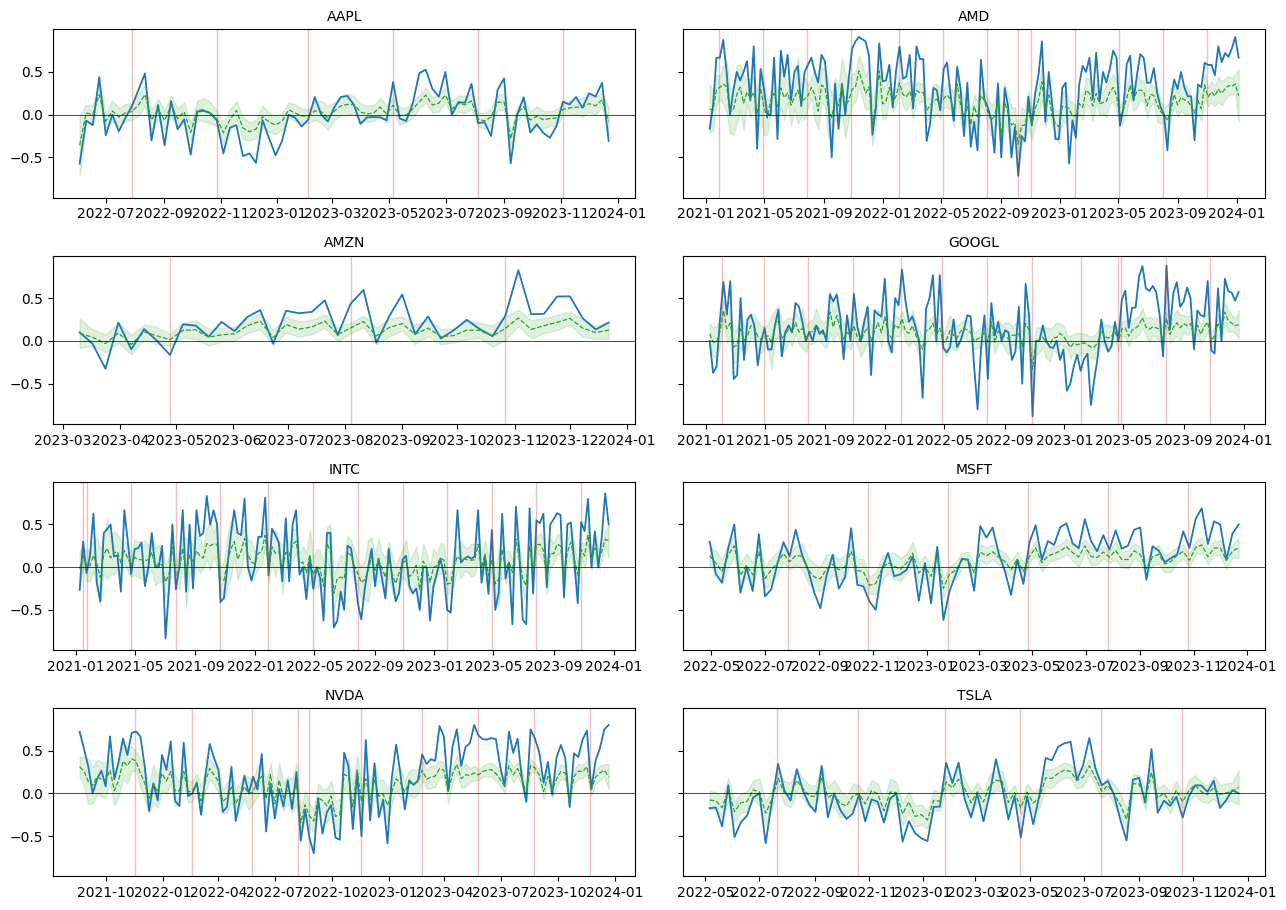

In [10]:
# Figures: TSLA weekly net tone with uncertainty + all tickers
def plot_ticker(ax, t):
    w = sent_weekly[(sent_weekly.ticker == t) & ~sent_weekly.insufficient].set_index("period")
    ax.plot(w.index, w.net_tone, lw=1.3, label="net tone")
    band = 1.96 * w.std_err.fillna(0)
    ax.plot(w.index, w.mean_score, lw=.9, ls="--", color="tab:green", label="mean score")
    ax.fill_between(w.index, w.mean_score - band, w.mean_score + band, color="tab:green", alpha=.15, label="mean score ±95% CI")
    ev = events[(events.ticker == t) & (events.ticker_scope != "ALL") & events.label.isin(["earnings"])]
    for d in ev.day0:
        if d >= w.index.min(): ax.axvline(d, color="tab:red", alpha=.3, lw=1)
    ax.axhline(0, color="k", lw=.5); ax.set_title(t, fontsize=10)

fig, ax = plt.subplots(figsize=(12, 3.4))
plot_ticker(ax, "TSLA" if "TSLA" in NEWS_TICKERS else NEWS_TICKERS[0])
ax.legend(fontsize=8); ax.set_title("TSLA weekly news sentiment (red lines = earnings day 0)")
plt.tight_layout(); plt.savefig(OUT / "figures" / "tsla_weekly_tone.png", dpi=150); plt.show()

n = len(NEWS_TICKERS); fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(13, 2.3 * ((n + 1) // 2)), sharey=True)
for ax, t in zip(axes.ravel(), NEWS_TICKERS):
    plot_ticker(ax, t)
plt.tight_layout(); plt.savefig(OUT / "figures" / "all_weekly_tone.png", dpi=130); plt.show()

## Step 6 — Embeddings for retrieval (GPU) + the time-blindness test

FNSPID documents are short (headline + summary), so **each document is one chunk**. Each chunk starts with a header `[TICKER | date | source]`, so the date is visible in the text. The embeddings are saved as float16.

**Time-blindness test.** For each ticker and year, we ask plain dense search *"What happened to {company} in {year}?"*, restricted to that company's documents but **without** a date filter, and measure what share of the top 20 results actually come from that year. If dense search understood time, the share would be close to 100%. If it is time-blind, the share stays near the **base rate** (that year's share of the company's documents). This result goes into the report's motivation section.

In [11]:
from sentence_transformers import SentenceTransformer

src = docs.publisher.fillna("nasdaq.com") if "publisher" in docs else "nasdaq.com"
chunks = docs[["doc_id", "ticker", "tickers_mentioned", "published_at", "available_at", "time_missing", "day0",
               "day0_safe", "title", "text_for_scoring", "url", "score", "label"]].copy()
chunks["chunk_text"] = ("[" + docs.ticker + " | " + docs.day0.dt.strftime("%Y-%m-%d") + " | " + src + "] "
                        + docs.text_for_scoring.astype(str))
chunks.to_parquet(OUT / "chunks.parquet", index=False)

emb = SentenceTransformer(EMBED_MODEL, device=DEVICE)
if DEVICE == "cuda":
    emb = emb.half()
t_emb = time.time()
E = emb.encode(chunks.chunk_text.tolist(), batch_size=EMB_BATCH, normalize_embeddings=True,
               convert_to_numpy=True, show_progress_bar=False).astype(np.float16)
np.save(OUT / "embeddings_bge.npy", E)
SUMMARY["embed_seconds"] = round(time.time() - t_emb)
print(f"Embeddings {E.shape} in {time.time()-t_emb:.0f}s → embeddings_bge.npy ({E.nbytes/1e6:.0f} MB)")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embeddings (49993, 768) in 161s → embeddings_bge.npy (77 MB)


In [12]:
COMPANY = {"TSLA": "Tesla", "AAPL": "Apple", "MSFT": "Microsoft", "NVDA": "Nvidia", "AMZN": "Amazon",
           "META": "Meta", "GOOGL": "Alphabet (Google)", "NFLX": "Netflix", "AMD": "AMD", "INTC": "Intel"}
Ef = E.astype(np.float32)
years_all = chunks.day0.dt.year.values
rows = []
for t in NEWS_TICKERS:
    idx_t = np.where(chunks.ticker.values == t)[0]
    for y in (2022, 2023):
        in_y = years_all[idx_t] == y
        if in_y.sum() < 200 or (~in_y).sum() < 200:      # need both years present to make the test meaningful
            continue
        q = emb.encode([QUERY_PREFIX + f"What happened to {COMPANY[t]} in {y}?"], normalize_embeddings=True)[0]
        top = idx_t[np.argsort(-(Ef[idx_t] @ q.astype(np.float32)))[:20]]
        rows.append({"ticker": t, "year_asked": y, "base_rate": round(in_y.mean(), 3),
                     "share_top20_from_year": round((years_all[top] == y).mean(), 3)})
time_blind = pd.DataFrame(rows)
time_blind.to_csv(OUT / "analysis" / "time_blindness.csv", index=False)
print(time_blind.to_string(index=False))
if len(time_blind):
    SUMMARY["time_blindness"] = {"mean_base_rate": round(time_blind.base_rate.mean(), 3),
                                 "mean_share_top20": round(time_blind.share_top20_from_year.mean(), 3), "pairs": len(time_blind)}
    print("\nMean share of top-20 from the asked year:", SUMMARY["time_blindness"])
del emb; torch.cuda.empty_cache() if DEVICE == "cuda" else None
print(f"\nGPU work finished at {time.time()-T0:.0f}s since start.")

ticker  year_asked  base_rate  share_top20_from_year
  AAPL        2022      0.353                   0.45
  AAPL        2023      0.647                   0.90
   AMD        2022      0.390                   0.50
   AMD        2023      0.440                   0.80
 GOOGL        2022      0.329                   0.45
 GOOGL        2023      0.409                   0.75
  INTC        2022      0.298                   0.60
  INTC        2023      0.447                   0.90
  MSFT        2022      0.307                   0.40
  MSFT        2023      0.693                   0.80
  NVDA        2022      0.276                   0.70
  NVDA        2023      0.645                   0.85
  TSLA        2022      0.366                   0.65
  TSLA        2023      0.634                   0.75

Mean share of top-20 from the asked year: {'mean_base_rate': np.float64(0.445), 'mean_share_top20': np.float64(0.679), 'pairs': 14}

GPU work finished at 444s since start.


## Step 7 — Does sentiment relate to abnormal returns?

Everything here runs per ticker, inside that ticker's coverage period. **S_t** = average main score of the articles dated on trading day *t* (the same-day mapping); **AR_t** = market-model abnormal return.

* **Lead–lag:** the correlation between S_t and AR_{t+k}, for k = −3…+3, pooled over tickers (each ticker is demeaned first).
  * **k = 0** is *contemporaneous*. Articles carry only a date, so this can't say which came first.
  * **k ≥ 1** is a **clean predictive test**: the articles were public before day t+k opened.
  * **k ≤ −1** asks whether news *follows* past price moves.
* **Granger tests** (lags 1–3), both directions, with a Bonferroni correction for the number of tests.
* **Event study:** the average CAR[−1,+3] and the average cumulative abnormal return path from day −5 to +10, per event type, plus the change in sentiment around events (mean S over days [0,+3] minus over [−5,−1]).

All of Step 7 is wrapped so that an error here can never lose the GPU results already saved.

Pooled correlation of S_t with AR_{t+k}:
          r     n  band_95
k                        
-3  0.0162  4175   0.0303
-2  0.0389  4180   0.0303
-1  0.0666  4184   0.0303
 0  0.2145  4188   0.0303
 1 -0.0097  4187   0.0303
 2  0.0038  4186   0.0303
 3 -0.0242  4185   0.0303


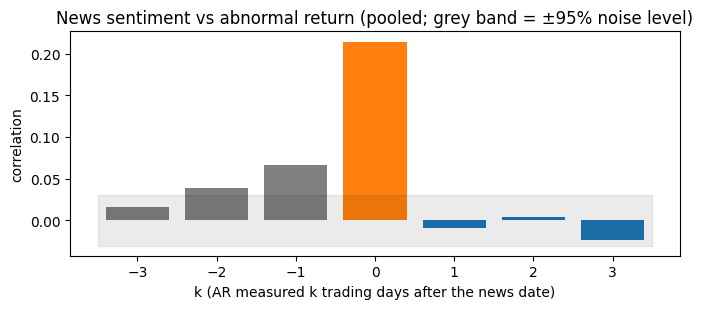


Granger tests: 48 total; Bonferroni threshold p < 0.00104
                     significant_0.05  significant_bonferroni
direction                                                    
returns → sentiment                 0                       0
sentiment → returns                 3                       0

Smallest p-values:
 ticker           direction  lag        p
  AMZN sentiment → returns    1 0.001200
  AMZN sentiment → returns    2 0.005584
  AMZN sentiment → returns    3 0.016704
  INTC returns → sentiment    1 0.062098
  INTC returns → sentiment    3 0.076180
  INTC returns → sentiment    2 0.076447


In [13]:
from statsmodels.tsa.stattools import grangercausalitytests, adfuller

def ticker_panel(t):
    p = prices[prices.ticker == t].set_index("date")[["ar", "ret"]]
    s = sent_daily[sent_daily.ticker == t].set_index("period")[["mean_score", "n_docs"]]
    df = p.join(s, how="left")
    df = df[(df.index >= COV_START[t]) & (df.index <= pd.Timestamp(END))]
    df["n_docs"] = df.n_docs.fillna(0)
    return df

PANELS = {t: ticker_panel(t) for t in NEWS_TICKERS}
analysis_ok = True
try:
    # ---------- lead-lag ----------
    ll_rows = []
    for k in range(-MAX_LAG, MAX_LAG + 1):
        xs, ys = [], []
        for t, df in PANELS.items():
            ar_k = df.ar.shift(-k)                          # AR_{t+k}
            ok = df.mean_score.notna() & ar_k.notna()
            x, y = df.mean_score[ok], ar_k[ok]
            if len(x) < 30: continue
            r_t = np.corrcoef(x, y)[0, 1]
            ll_rows.append({"k": k, "ticker": t, "r": r_t, "n": len(x)})
            xs.append(x - x.mean()); ys.append(y - y.mean())
        X, Y = np.concatenate(xs), np.concatenate(ys)
        ll_rows.append({"k": k, "ticker": "POOLED", "r": np.corrcoef(X, Y)[0, 1], "n": len(X)})
    lead_lag = pd.DataFrame(ll_rows)
    lead_lag["band_95"] = 1.96 / np.sqrt(lead_lag.n)
    lead_lag.to_csv(OUT / "analysis" / "lead_lag.csv", index=False)
    pooled = lead_lag[lead_lag.ticker == "POOLED"].set_index("k")
    print("Pooled correlation of S_t with AR_{t+k}:\n", pooled[["r", "n", "band_95"]].round(4).to_string())
    SUMMARY["lead_lag_pooled"] = pooled.r.round(4).to_dict()

    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.bar(pooled.index, pooled.r, color=["tab:gray" if k < 0 else ("tab:orange" if k == 0 else "tab:blue") for k in pooled.index])
    ax.fill_between([-MAX_LAG - .5, MAX_LAG + .5], -pooled.band_95.mean(), pooled.band_95.mean(), color="k", alpha=.08)
    ax.set_xlabel("k (AR measured k trading days after the news date)"); ax.set_ylabel("correlation")
    ax.set_title("News sentiment vs abnormal return (pooled; grey band = ±95% noise level)")
    plt.tight_layout(); plt.savefig(OUT / "figures" / "lead_lag.png", dpi=150); plt.show()

    # ---------- Granger ----------
    g_rows = []
    for t, df in PANELS.items():
        d = pd.DataFrame({"ar": df.ar, "s": df.mean_score.fillna(0.0)}).dropna()
        if len(d) < 100: continue
        adf_s, adf_ar = adfuller(d.s)[1], adfuller(d.ar)[1]
        for direction, cols in [("sentiment → returns", ["ar", "s"]), ("returns → sentiment", ["s", "ar"])]:
            with contextlib.redirect_stdout(io.StringIO()):
                res = grangercausalitytests(d[cols], maxlag=MAX_LAG)
            for lag in range(1, MAX_LAG + 1):
                g_rows.append({"ticker": t, "direction": direction, "lag": lag, "n": len(d),
                               "F": res[lag][0]["ssr_ftest"][0], "p": res[lag][0]["ssr_ftest"][1],
                               "adf_p_sentiment": adf_s, "adf_p_returns": adf_ar})
    granger = pd.DataFrame(g_rows)
    n_tests = len(granger)
    granger["significant_bonferroni"] = granger.p < 0.05 / max(n_tests, 1)
    granger["significant_0.05"] = granger.p < 0.05
    granger.to_csv(OUT / "analysis" / "granger.csv", index=False)
    summ_g = granger.groupby("direction")[["significant_0.05", "significant_bonferroni"]].sum()
    print(f"\nGranger tests: {n_tests} total; Bonferroni threshold p < {0.05/max(n_tests,1):.5f}")
    print(summ_g.to_string())
    print("\nSmallest p-values:\n", granger.nsmallest(6, "p")[["ticker", "direction", "lag", "p"]].to_string(index=False))
    SUMMARY["granger"] = {d: {"sig_0.05": int(r["significant_0.05"]), "sig_bonferroni": int(r["significant_bonferroni"]),
                              "tests": int((granger.direction == d).sum())} for d, r in summ_g.iterrows()}
except Exception as e:
    analysis_ok = False
    import traceback; traceback.print_exc()
    print("⚠️ Lead-lag/Granger failed — GPU outputs are already saved; send the error back.")

/tmp/ipykernel_22/1423581557.py:18: RuntimeWarning: Mean of empty slice
  before, after = np.nanmean(s[i - 5:i]), np.nanmean(s[i:i + 4])


Event study (company events within coverage; FOMC expanded per ticker):
                      n  mean_CAR  mean_abs_CAR  share_negative  mean_sent_shift
label                                                                          
FOMC decision      138    0.0063        0.0317          0.4493           0.0316
deliveries report    6   -0.0269        0.0635          0.5000          -0.0874
earnings            72    0.0103        0.0579          0.4306          -0.0235
leadership change   41   -0.0083        0.0322          0.5610           0.0504
price shock        149    0.0067        0.0547          0.4698          -0.0086

Earnings, split by the stock's day-0 reaction:
            n  mean_CAR  mean_sent_shift
reaction                               
down      36   -0.0406          -0.1374
up        36    0.0611           0.0904


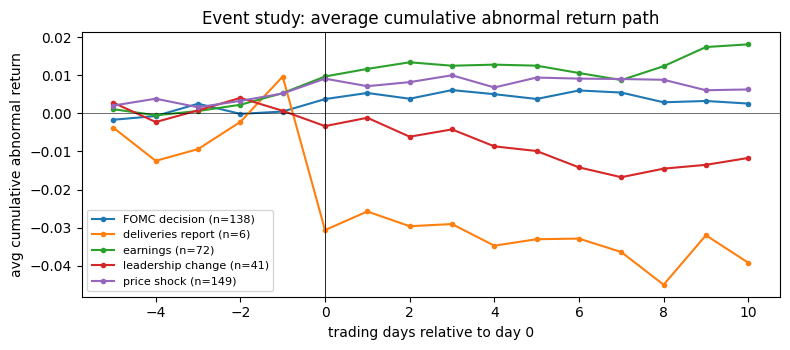


News volume vs |abnormal return| (same day):
 ticker  corr_ndocs_absAR
  AAPL             0.276
   AMD             0.301
  AMZN             0.184
 GOOGL             0.258
  INTC             0.452
  MSFT             0.303
  NVDA             0.292
  TSLA             0.385


In [14]:
try:
    ev = events[(events.ticker_scope != "ALL") & events.ticker.isin(NEWS_TICKERS)].copy()
    ev = ev[[d >= COV_START[t] for t, d in zip(ev.ticker, ev.day0)]]
    fomc = events[(events.ticker_scope == "ALL") & events.ticker.isin(NEWS_TICKERS)].copy()
    fomc = fomc[[d >= COV_START[t] for t, d in zip(fomc.ticker, fomc.day0)]]
    allev = pd.concat([ev, fomc], ignore_index=True)

    path_rows, shift_rows = [], []
    for e in allev.itertuples():
        df = PANELS[e.ticker]
        if e.day0 not in df.index: continue
        i = df.index.get_loc(e.day0)
        if i - 5 < 0 or i + 10 >= len(df): continue
        ar = df.ar.values
        cum = np.cumsum(ar[i - 5:i + 11])
        path_rows.append(pd.DataFrame({"label": e.label, "k": np.arange(-5, 11), "cum_ar": cum}))
        s = df.mean_score.values
        before, after = np.nanmean(s[i - 5:i]), np.nanmean(s[i:i + 4])
        shift_rows.append({"label": e.label, "ticker": e.ticker, "car_m1_p3": e.car_m1_p3,
                           "ar_day0": e.ar_day0, "sent_before": before, "sent_after": after,
                           "sent_shift": after - before})
    paths = pd.concat(path_rows)
    shifts = pd.DataFrame(shift_rows)
    shifts["reaction"] = np.where(shifts.ar_day0 >= 0, "up", "down")
    study = shifts.groupby("label").agg(n=("car_m1_p3", "size"), mean_CAR=("car_m1_p3", "mean"),
                                        mean_abs_CAR=("car_m1_p3", lambda x: x.abs().mean()),
                                        share_negative=("car_m1_p3", lambda x: (x < 0).mean()),
                                        mean_sent_shift=("sent_shift", "mean")).round(4)
    by_reaction = shifts[shifts.label == "earnings"].groupby("reaction").agg(
        n=("sent_shift", "size"), mean_CAR=("car_m1_p3", "mean"), mean_sent_shift=("sent_shift", "mean")).round(4)
    print("Event study (company events within coverage; FOMC expanded per ticker):\n", study.to_string())
    print("\nEarnings, split by the stock's day-0 reaction:\n", by_reaction.to_string())
    study.to_csv(OUT / "analysis" / "event_study.csv"); by_reaction.to_csv(OUT / "analysis" / "earnings_by_reaction.csv")
    paths.groupby(["label", "k"]).cum_ar.mean().unstack(0).to_csv(OUT / "analysis" / "event_paths.csv")
    SUMMARY["event_study"] = study[["n", "mean_abs_CAR", "mean_sent_shift"]].to_dict("index")
    SUMMARY["earnings_by_reaction"] = by_reaction.to_dict("index")

    fig, ax = plt.subplots(figsize=(8, 3.6))
    avg = paths.groupby(["label", "k"]).cum_ar.mean().unstack(0)
    for lab in avg.columns:
        ax.plot(avg.index, avg[lab], marker="o", ms=3, label=f"{lab} (n={int(study.loc[lab, 'n']) if lab in study.index else 0})")
    ax.axvline(0, color="k", lw=.6); ax.axhline(0, color="k", lw=.4)
    ax.set_xlabel("trading days relative to day 0"); ax.set_ylabel("avg cumulative abnormal return")
    ax.set_title("Event study: average cumulative abnormal return path"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(OUT / "figures" / "event_paths.png", dpi=150); plt.show()

    # attention: news volume vs size of the move
    att = []
    for t, df in PANELS.items():
        ok = df.ar.notna()
        att.append({"ticker": t, "corr_ndocs_absAR": np.corrcoef(df.n_docs[ok], df.ar[ok].abs())[0, 1]})
    att = pd.DataFrame(att).round(3); att.to_csv(OUT / "analysis" / "attention.csv", index=False)
    print("\nNews volume vs |abnormal return| (same day):\n", att.to_string(index=False))
    SUMMARY["attention_mean_corr"] = round(att.corr_ndocs_absAR.mean(), 3)
except Exception:
    import traceback; traceback.print_exc()
    print("⚠️ Event study failed — other outputs are saved; send the error back.")

In [15]:
# ---------------- SAVE + SUMMARY ----------------
for name in ("prices.parquet", "trading_days.parquet"):
    shutil.copy(find_input(name), OUT / name)
events.to_parquet(OUT / "events_labeled.parquet", index=False)
coverage_span.to_csv(OUT / "coverage_span.csv", index=False)
docs.to_parquet(OUT / "documents_scored.parquet", index=False)

manifest = {"created": pd.Timestamp.now(tz="Asia/Kolkata").isoformat(), "news_tickers": NEWS_TICKERS,
            "dropped_tickers": dropped, "finbert": FINBERT_MODEL, "embedder": EMBED_MODEL,
            "query_prefix": QUERY_PREFIX, "min_week_docs": MIN_WEEK_DOCS, "end": END,
            "files": sorted(str(p.relative_to(OUT)) for p in OUT.rglob("*") if p.is_file())}
(OUT / "manifest_nb2.json").write_text(json.dumps(manifest, indent=2, default=str))
for f in sorted(OUT.rglob("*")):
    if f.is_file(): print(f"{str(f.relative_to(OUT)):40s} {f.stat().st_size/1e6:8.2f} MB")

SUMMARY["total_minutes"] = round((time.time() - T0) / 60, 1)
print("\n" + "=" * 30 + " SUMMARY (send this back) " + "=" * 30)
print(json.dumps(SUMMARY, indent=1, default=str))

analysis/attention.csv                       0.00 MB
analysis/earnings_by_reaction.csv            0.00 MB
analysis/event_paths.csv                     0.00 MB
analysis/event_study.csv                     0.00 MB
analysis/granger.csv                         0.01 MB
analysis/lead_lag.csv                        0.00 MB
analysis/time_blindness.csv                  0.00 MB
chunks.parquet                              32.41 MB
coverage_span.csv                            0.00 MB
documents_scored.parquet                    19.61 MB
embeddings_bge.npy                          76.79 MB
events_labeled.parquet                       0.04 MB
figures/all_weekly_tone.png                  0.56 MB
figures/event_paths.png                      0.10 MB
figures/lead_lag.png                         0.04 MB
figures/tsla_weekly_tone.png                 0.20 MB
manifest_nb2.json                            0.00 MB
prices.parquet                               0.83 MB
sentiment_daily.parquet                      0